## Retail Performance Intelligence
## Exploratory Data Analysis (EDA)
Objetivo: explorar os dados de vendas, clientes e produtos para identificar padrões,
tendências e oportunidades de negócio relevantes para a gestão comercial.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "retail_sales_clean.csv",
    parse_dates=["transaction_date"]
)

In [3]:
df.head()

,transaction_id,transaction_date,customer_id,customer_gender,customer_age_group,customer_segment,product_id,product_name,category,brand,quantity,unit_price,discount_pct,sales_amount,payment_method,sales_channel,region
0,T0000001,2024-04-24,C000820,Other,35-44,Returning,P1082,Dumbbells,Sports,Brand 1,2,313.53,20,501.65,Debit Card,Online,North
1,T0000002,2025-07-12,C002849,Other,45-54,New,P1087,Running Shoes,Sports,Brand 3,1,366.16,0,366.16,Credit Card,Online,South
2,T0000003,2025-06-01,C019727,Male,55+,Returning,P1030,Sneakers,Clothing,Brand 3,1,27.99,0,27.99,Gift Card,In-Store,South
3,T0000004,2025-08-26,C009116,Male,25-34,VIP,P1058,Sunscreen,Beauty,Brand 1,2,102.01,15,173.42,Cash,In-Store,South
4,T0000005,2024-12-10,C003350,Male,45-54,New,P1028,Sneakers,Clothing,Brand 1,1,259.55,0,259.55,Cash,In-Store,Central


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      120000 non-null  str           
 1   transaction_date    120000 non-null  datetime64[us]
 2   customer_id         120000 non-null  str           
 3   customer_gender     120000 non-null  str           
 4   customer_age_group  120000 non-null  str           
 5   customer_segment    120000 non-null  str           
 6   product_id          120000 non-null  str           
 7   product_name        120000 non-null  str           
 8   category            120000 non-null  str           
 9   brand               120000 non-null  str           
 10  quantity            120000 non-null  int64         
 11  unit_price          120000 non-null  float64       
 12  discount_pct        120000 non-null  int64         
 13  sales_amount        120000 non-null  flo

In [5]:
df.shape

(120000, 17)

In [6]:
df["transaction_date"].min()

Timestamp('2024-01-01 00:00:00')

In [7]:
df["transaction_date"].max()

Timestamp('2025-12-30 00:00:00')

## 1. Performance geral de vendas

Nesta etapa, serão calculados os principais indicadores de desempenho comercial:
receita total, número de transações e ticket médio.

In [8]:
total_revenue = df["sales_amount"].sum()

print(f"Receita total: {total_revenue:,.2f}")

Receita total: 45,357,054.45


In [9]:
total_transactions = df["transaction_id"].nunique()

print(f"Total de transações: {total_transactions:,}")

Total de transações: 120,000


In [10]:
average_ticket = total_revenue / total_transactions

print(f"Ticket médio: {average_ticket:,.2f}")

Ticket médio: 377.98


In [11]:

df[['quantity', 'unit_price', 'discount_pct', 'sales_amount']].median()

quantity          1.00
unit_price      238.75
discount_pct      0.00
sales_amount    295.98
dtype: float64

In [12]:
# Estatísticas descritivas
df[['quantity', 'unit_price', 'discount_pct', 'sales_amount']].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,120000.0,1.662908,1.014291,1.00,1.00,1.00,2.0,5.00
unit_price,120000.0,240.621785,146.457057,7.73,102.01,238.75,379.0,493.51
discount_pct,120000.0,5.496500,8.193257,0.00,0.00,0.00,10.0,30.00
sales_amount,120000.0,377.975454,356.893357,5.41,136.86,295.98,461.5,2467.55


In [13]:
df['sales_amount'].mean(), df['sales_amount'].median()

(np.float64(377.97545375000004), 295.98)

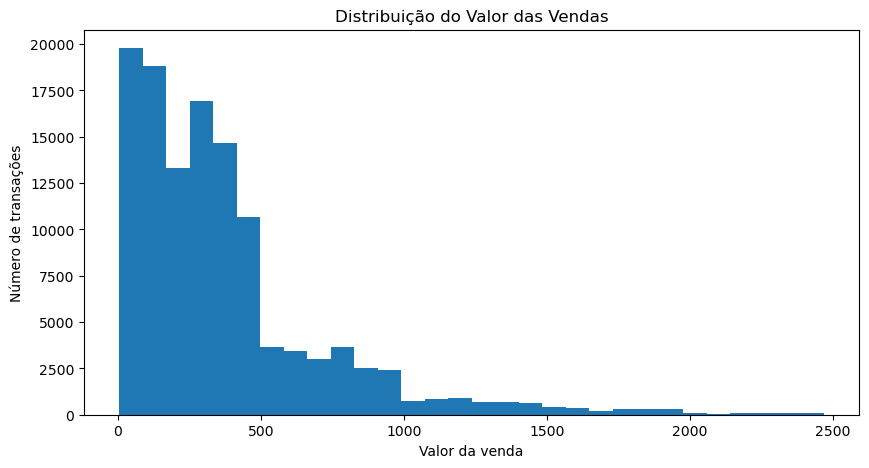

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['sales_amount'], bins=30)

plt.title('Distribuição do Valor das Vendas')
plt.xlabel('Valor da venda')
plt.ylabel('Número de transações')

plt.show()

In [15]:
Q1 = df['sales_amount'].quantile(0.25)
Q3 = df['sales_amount'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

Q1: 136.86
Q3: 461.50
IQR: 324.64
Limite inferior: -350.10
Limite superior: 948.46


In [16]:
outliers = df[df['sales_amount'] > limite_superior]

print(f"Número de possíveis outliers: {len(outliers):,}")
print(f"Percentual das transações: {len(outliers) / len(df) * 100:.2f}%")

Número de possíveis outliers: 8,309
Percentual das transações: 6.92%


In [17]:
receita_outliers = outliers['sales_amount'].sum()
receita_total = df['sales_amount'].sum()

percentual_receita = receita_outliers / receita_total * 100

print(f"Receita dos possíveis outliers: €{receita_outliers:,.2f}")
print(f"Receita total: €{receita_total:,.2f}")
print(f"Percentual da receita: {percentual_receita:.2f}%")

Receita dos possíveis outliers: €11,358,338.19
Receita total: €45,357,054.45
Percentual da receita: 25.04%


In [18]:
revenue_by_category = (
    df.groupby('category')['sales_amount']
      .sum()
      .sort_values(ascending=False)
)

revenue_by_category

category
Beauty         6355718.23
Books          6005237.69
Sports         5863370.76
Electronics    5859686.69
Home           5655562.80
Toys           5557562.19
Groceries      5431536.64
Clothing       4628379.45
Name: sales_amount, dtype: float64

In [19]:
quantity_by_category = (
    df.groupby('category')['quantity']
      .sum()
      .sort_values(ascending=False)
)

quantity_by_category

category
Clothing       25223
Sports         25183
Beauty         25171
Groceries      25109
Toys           25039
Home           24916
Electronics    24866
Books          24042
Name: quantity, dtype: int64

In [20]:
ticket_by_category = (
    df.groupby('category')['sales_amount']
      .mean()
      .sort_values(ascending=False)
)

ticket_by_category

category
Beauty         421.662458
Books          412.560984
Electronics    390.437546
Sports         385.291810
Home           378.729177
Toys           369.961536
Groceries      361.283533
Clothing       305.382650
Name: sales_amount, dtype: float64

In [21]:
monthly_sales = (
    df.groupby(df['transaction_date'].dt.to_period('M'))['sales_amount']
      .sum()
)

monthly_sales

transaction_date
2024-01    1980147.17
2024-02    1797169.80
2024-03    1885630.00
2024-04    1862123.73
2024-05    1946801.10
2024-06    1892102.05
2024-07    1907030.93
2024-08    1947600.00
2024-09    1858013.87
2024-10    1833992.24
2024-11    1955443.63
2024-12    1920349.49
2025-01    1925284.04
2025-02    1793455.91
2025-03    1813051.32
2025-04    1862967.35
2025-05    1921171.94
2025-06    1838634.83
2025-07    2007036.02
2025-08    1967685.22
2025-09    1836361.30
2025-10    1949976.97
2025-11    1783231.12
2025-12    1871794.42
Freq: M, Name: sales_amount, dtype: float64

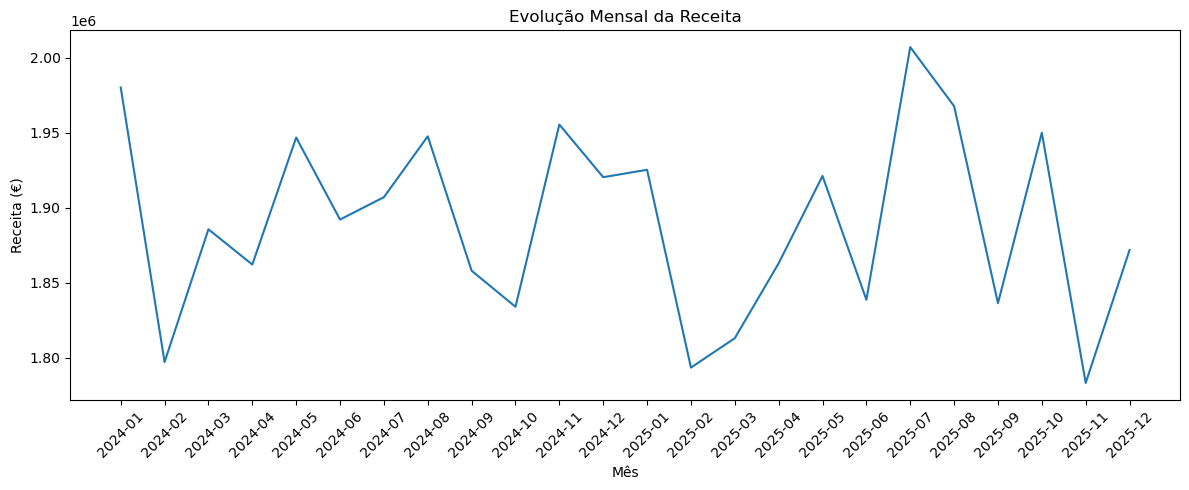

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title('Evolução Mensal da Receita')
plt.xlabel('Mês')
plt.ylabel('Receita (€)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

A receita apresenta oscilações mensais, sem crescimento consistente entre 2024 e 2025. Isso indica a necessidade de investigar quais categorias, produtos ou segmentos estão contribuindo para os picos e quedas de desempenho.

In [23]:
category_analysis = (
    df.groupby('category')
      .agg(
          revenue=('sales_amount', 'sum'),
          quantity=('quantity', 'sum'),
          transactions=('transaction_id', 'nunique')
      )
      .sort_values('revenue', ascending=False)
)

category_analysis

,revenue,quantity,transactions
category,,,
Beauty,6355718.23,25171,15073
Books,6005237.69,24042,14556
Sports,5863370.76,25183,15218
Electronics,5859686.69,24866,15008
Home,5655562.80,24916,14933
Toys,5557562.19,25039,15022
Groceries,5431536.64,25109,15034
Clothing,4628379.45,25223,15156


In [24]:
revenue_by_segment = (
    df.groupby('customer_segment')['sales_amount']
      .agg(['sum', 'mean', 'count'])
      .sort_values('sum', ascending=False)
)

revenue_by_segment

,sum,mean,count
customer_segment,,,
Loyal,11393721.23,379.613555,30014
New,11331906.60,377.478568,30020
VIP,11320171.31,375.898101,30115
Returning,11311255.31,378.923832,29851


In [25]:
segment_share = (
    df.groupby('customer_segment')['sales_amount']
      .sum()
      .div(df['sales_amount'].sum())
      .mul(100)
      .sort_values(ascending=False)
)

segment_share

customer_segment
Loyal        25.120064
New          24.983780
VIP          24.957907
Returning    24.938249
Name: sales_amount, dtype: float64

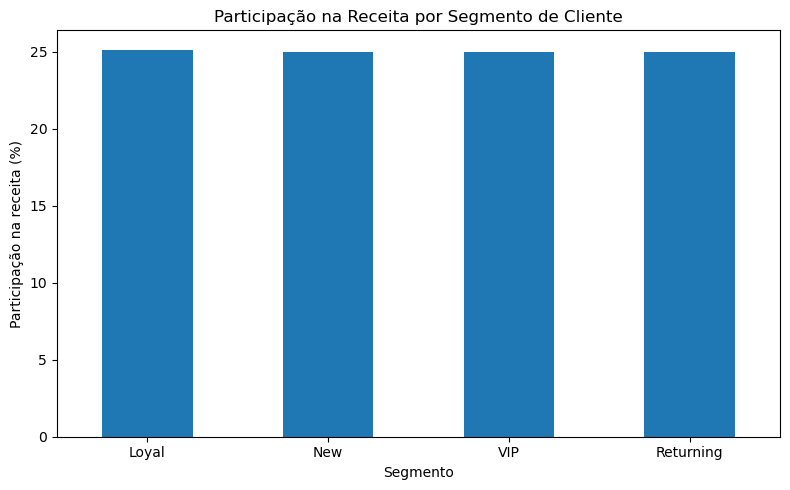

In [26]:
plt.figure(figsize=(8, 5))

segment_share.plot(kind='bar')

plt.title('Participação na Receita por Segmento de Cliente')
plt.xlabel('Segmento')
plt.ylabel('Participação na receita (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [27]:
df['discount_pct'].describe()

count    120000.000000
mean          5.496500
std           8.193257
min           0.000000
25%           0.000000
50%           0.000000
75%          10.000000
max          30.000000
Name: discount_pct, dtype: float64

In [28]:
discounted_sales = (df['discount_pct'] > 0).sum()

discounted_share = discounted_sales / len(df) * 100

print(f"Transações com desconto: {discounted_sales:,}")
print(f"Percentual de transações com desconto: {discounted_share:.2f}%")

Transações com desconto: 48,044
Percentual de transações com desconto: 40.04%


In [29]:
discount_comparison = (
    df.groupby(df['discount_pct'] > 0)['sales_amount']
    .agg(['mean', 'median', 'count'])
)

discount_comparison.index = ['Sem desconto', 'Com desconto']

discount_comparison

,mean,median,count
Sem desconto,399.465509,307.87,71956
Com desconto,345.789574,268.43,48044


As transações com desconto apresentam, neste conjunto de dados, um valor médio e mediano inferior às transações sem desconto.

In [30]:
discount_analysis = (
    df.groupby('discount_pct')['sales_amount']
    .agg(['mean', 'median', 'count'])
    .sort_index()
)

discount_analysis

,mean,median,count
discount_pct,,,
0,399.465509,307.870,71956
5,381.917852,294.580,12042
10,360.452565,277.080,12033
15,339.633701,264.520,9653
20,323.275968,249.345,7162
25,299.897565,230.900,4723
30,274.179770,214.220,2431


Observa-se uma associação negativa entre o percentual de desconto e o valor médio das transações: quanto maior o desconto aplicado, menor o ticket médio observado.

In [31]:
quantity_by_discount = (
    df.groupby('discount_pct')['quantity']
    .agg(['mean', 'median', 'sum', 'count'])
    .sort_index()
)

quantity_by_discount

,mean,median,sum,count
discount_pct,,,,
0,1.663753,1.0,119717,71956
5,1.644577,1.0,19804,12042
10,1.664007,1.0,20023,12033
15,1.670465,1.0,16125,9653
20,1.673276,1.0,11984,7162
25,1.662079,1.0,7850,4723
30,1.664336,1.0,4046,2431


### Insight — Descontos e comportamento de compra

As transações com maiores percentuais de desconto apresentam valores médios de venda progressivamente menores. Entretanto, a quantidade média de itens por transação permanece praticamente estável em todos os níveis de desconto.

Esse padrão sugere uma associação entre descontos maiores e tickets menores, sem evidência descritiva de aumento relevante na quantidade de itens comprados por transação.

> Observação: essa análise identifica associação, não causalidade.

In [32]:
channel_analysis = (
    df.groupby('sales_channel')['sales_amount']
      .agg(['sum', 'mean', 'median', 'count'])
      .sort_values('sum', ascending=False)
)

channel_analysis

,sum,mean,median,count
sales_channel,,,,
In-Store,15273226.27,381.363486,298.250,40049
Mobile App,15065983.38,374.738419,290.695,40204
Online,15017844.80,377.835932,294.340,39747


A receita e o volume de transações estão distribuídos de forma equilibrada entre In-Store, Mobile App e Online. O canal In-Store apresenta o maior ticket médio, porém a diferença entre os canais é pequena.

In [33]:
discount_by_channel = (
    df.groupby('sales_channel')['discount_pct']
      .agg(['mean', 'median', 'count'])
)

discount_by_channel

,mean,median,count
sales_channel,,,
In-Store,5.464431,0.0,40049
Mobile App,5.564620,0.0,40204
Online,5.459909,0.0,39747


A política de descontos apresenta comportamento bastante semelhante entre os três canais de venda, sem diferenças relevantes no desconto médio.

In [34]:
region_analysis = (
    df.groupby('region')['sales_amount']
      .agg(['sum', 'mean', 'median', 'count'])
      .sort_values('sum', ascending=False)
)

region_analysis

,sum,mean,median,count
region,,,,
Central,9237924.11,381.039602,298.25,24244
West,9106911.70,380.246835,295.94,23950
North,9049438.11,375.885280,297.85,24075
South,8991262.89,373.608530,292.93,24066
East,8971517.64,379.104908,291.52,23665


A performance comercial apresenta distribuição geográfica equilibrada. A região Central possui a maior receita e ticket médio, enquanto a região South apresenta o menor ticket médio, porém as diferenças entre as regiões são relativamente pequenas.

In [35]:
product_analysis = (
    df.groupby('product_name')
      .agg(
          revenue=('sales_amount', 'sum'),
          quantity=('quantity', 'sum'),
          transactions=('transaction_id', 'nunique')
      )
      .sort_values('revenue', ascending=False)
)

product_analysis.head(10)

,revenue,quantity,transactions
product_name,,,
Bread,2073770.79,4824,2926
Lipstick,2063017.35,5013,2990
Textbook,1737817.74,4763,2869
Smartphone,1631875.41,5046,3015
Water Bottle,1605400.95,5021,3028
Storage Box,1509331.33,4878,2949
Notebook,1478248.61,4870,2937
Toy Car,1423744.56,4907,2985
Building Blocks,1394417.17,5087,3013


In [36]:
product_analysis['avg_transaction_value'] = (
    product_analysis['revenue'] /
    product_analysis['transactions']
)

product_analysis.head(10)

,revenue,quantity,transactions,avg_transaction_value
product_name,,,,
Bread,2073770.79,4824,2926,708.739163
Lipstick,2063017.35,5013,2990,689.972358
Textbook,1737817.74,4763,2869,605.722461
Smartphone,1631875.41,5046,3015,541.252209
Water Bottle,1605400.95,5021,3028,530.185254
Storage Box,1509331.33,4878,2949,511.811234
Notebook,1478248.61,4870,2937,503.319241
Toy Car,1423744.56,4907,2985,476.966352
Building Blocks,1394417.17,5087,3013,462.800256


In [37]:
product_analysis['avg_sales_per_transaction'] = (
    product_analysis['revenue'] /
    product_analysis['transactions']
)

Os produtos apresentam volumes de transações semelhantes, mas valores médios por transação diferentes. Os produtos com maior receita, como Bread e Lipstick, também apresentam os maiores valores médios por transação, indicando que o valor gerado por compra é um fator relevante para o desempenho dos produtos.

In [38]:
product_analysis['units_per_transaction'] = (
    product_analysis['quantity'] /
    product_analysis['transactions']
)

product_analysis.head(10)

,revenue,quantity,transactions,avg_transaction_value,avg_sales_per_transaction,units_per_transaction
product_name,,,,,,
Bread,2073770.79,4824,2926,708.739163,708.739163,1.648667
Lipstick,2063017.35,5013,2990,689.972358,689.972358,1.676589
Textbook,1737817.74,4763,2869,605.722461,605.722461,1.660160
Smartphone,1631875.41,5046,3015,541.252209,541.252209,1.673632
Water Bottle,1605400.95,5021,3028,530.185254,530.185254,1.658190
Storage Box,1509331.33,4878,2949,511.811234,511.811234,1.654120
Notebook,1478248.61,4870,2937,503.319241,503.319241,1.658155
Toy Car,1423744.56,4907,2985,476.966352,476.966352,1.643886
Building Blocks,1394417.17,5087,3013,462.800256,462.800256,1.688350


In [39]:
bottom_5_products = product_analysis.sort_values(
    by='revenue',
    ascending=True
).head(5)

bottom_5_products[
    ['revenue', 'quantity', 'transactions', 'avg_sales_per_transaction']
]

,revenue,quantity,transactions,avg_sales_per_transaction
product_name,,,,
Cookbook,463695.12,4735,2875,161.285259
Sunscreen,465357.58,5050,3013,154.449910
Doll,633447.16,4950,2986,212.139035
Jacket,660467.08,5116,3017,218.915174
Milk,708199.10,5080,3033,233.497890


### Análise dos produtos com menor receita

Cookbook e Sunscreen apresentam as menores receitas totais entre os produtos analisados, enquanto Milk apresenta a maior receita dentro deste grupo.

Apesar de os produtos apresentarem quantidades vendidas e números de transações relativamente semelhantes, existem diferenças nos valores médios gerados por transação.

Estes resultados mostram que o volume de vendas, isoladamente, não explica todas as diferenças de receita entre os produtos. No entanto, a análise não permite concluir sobre a rentabilidade, uma vez que não temos dados de custos.

In [40]:
product_analysis['revenue_share_pct'] = (
    product_analysis['revenue'] / df['sales_amount'].sum()
) * 100

product_analysis.sort_values(
    by='revenue',
    ascending=False
)[['revenue', 'revenue_share_pct']].head(10)

,revenue,revenue_share_pct
product_name,,
Bread,2073770.79,4.572102
Lipstick,2063017.35,4.548394
Textbook,1737817.74,3.831417
Smartphone,1631875.41,3.597843
Water Bottle,1605400.95,3.539474
Storage Box,1509331.33,3.327666
Notebook,1478248.61,3.259137
Toy Car,1423744.56,3.138971
Building Blocks,1394417.17,3.074312


### Participação dos produtos na receita total

Bread e Lipstick apresentam as maiores participações individuais na receita total, com aproximadamente 4,57% e 4,55%, respetivamente.

Os dez produtos com maior receita representam, em conjunto, cerca de 35,86% da receita total. Apesar de estes produtos terem um contributo relevante para as vendas, nenhum deles representa individualmente uma parcela muito elevada da receita.

Estes resultados sugerem que a receita está distribuída por vários produtos. Para avaliar a concentração global, seria necessário considerar a participação de todos os produtos.

In [41]:
top_5_share = product_analysis.nlargest(5, 'revenue')['revenue_share_pct'].sum()

top_10_share = product_analysis.nlargest(10, 'revenue')['revenue_share_pct'].sum()

print(f"Participação dos 5 produtos principais: {top_5_share:.2f}%")
print(f"Participação dos 10 produtos principais: {top_10_share:.2f}%")

Participação dos 5 produtos principais: 20.09%
Participação dos 10 produtos principais: 35.86%


### Participação acumulada dos produtos

Os cinco produtos com maior receita representam 20,09% da receita total, enquanto os dez principais representam 35,86%.

Consequentemente, os restantes produtos contribuem com aproximadamente 64,14% da receita.

Estes resultados indicam que uma parcela significativa da receita é gerada por produtos fora do grupo dos dez principais. Assim, a análise do desempenho comercial deve considerar o conjunto do portfólio, e não apenas os produtos líderes.

## Conclusão da Análise Exploratória de Dados (EDA)

A análise exploratória dos dados de vendas permitiu compreender melhor o desempenho comercial da empresa, identificando padrões relacionados com a evolução da receita, categorias de produtos, segmentos de clientes, descontos, canais de venda, regiões e produtos individuais.

O conjunto de dados contém 120.000 transações, abrangendo o período de 1 de janeiro de 2024 a 30 de dezembro de 2025. Durante esse período, a receita total foi de aproximadamente €45,36 milhões, com um valor médio por transação de €377,98. A distribuição dos valores das vendas apresenta assimetria à direita, indicando que, embora muitas transações tenham valores mais baixos, existe também um conjunto de transações de valor elevado.

Na análise temporal, observou-se que a receita de 2025 foi aproximadamente 0,95% inferior à de 2024. A receita mensal apresentou oscilações ao longo dos dois anos, sem evidência de uma tendência contínua de crescimento. Julho de 2025 registou a maior receita mensal, enquanto novembro de 2025 apresentou a menor.

Relativamente às categorias, Beauty apresentou a maior receita, enquanto Clothing registou a menor. Apesar dessas diferenças, os resultados das categorias foram relativamente próximos, sugerindo que o desempenho comercial não depende exclusivamente de uma única categoria.

A análise dos segmentos de clientes revelou uma distribuição bastante equilibrada da receita entre Loyal, New, VIP e Returning, com participações próximas de 25% cada. Isso mostra que os quatro segmentos contribuíram de forma semelhante para a receita total durante o período analisado.

Na análise dos descontos, aproximadamente 40,04% das transações apresentaram algum desconto. Observou-se uma associação negativa entre o nível de desconto e o valor médio por transação: transações sem desconto apresentaram valores médios superiores aos das transações com desconto, e o valor médio diminuiu à medida que o desconto aumentou. No entanto, essa relação é descritiva e não permite concluir que os descontos sejam a causa das diferenças observadas. Além disso, a quantidade média de unidades por transação manteve-se relativamente estável entre os diferentes níveis de desconto.

Quanto aos canais de venda, In-Store, Mobile App e Online apresentaram receitas e volumes de transações semelhantes. O canal In-Store registou a maior receita, mas as diferenças entre os canais foram pequenas. As médias de desconto também foram próximas entre os três canais.

A análise regional mostrou resultados igualmente equilibrados. Central apresentou a maior receita e o maior valor médio por transação, enquanto South registou o menor valor médio. Ainda assim, as diferenças entre as regiões foram relativamente pequenas.

Na análise dos produtos, Bread e Lipstick destacaram-se pelas maiores receitas individuais, com participações de aproximadamente 4,57% e 4,55% da receita total, respetivamente. Os cinco produtos com maior receita representaram 20,09% do total, enquanto os dez principais representaram 35,86%. Isso demonstra que uma parcela significativa da receita também é gerada pelos restantes produtos do portfólio.

De forma geral, a análise revelou um desempenho relativamente equilibrado entre segmentos de clientes, canais de venda, regiões e categorias, embora existam diferenças específicas entre produtos e níveis de desconto. Esses resultados fornecem uma base para acompanhar o desempenho comercial por meio de indicadores e visualizações.

Como limitações, esta análise é essencialmente descritiva. Os resultados identificam padrões e associações, mas não demonstram relações de causa e efeito. Além disso, como o conjunto de dados não inclui informações de custos, não é possível avaliar a rentabilidade dos produtos ou determinar o impacto dos descontos sobre o lucro.

Os resultados desta EDA serão utilizados como base para a construção de um dashboard em Tableau, permitindo acompanhar os principais KPIs e explorar o desempenho das vendas por diferentes dimensões do negócio.